In [1]:
import mne
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.model_selection import KFold
from mne.decoding import ReceptiveField

data = loadmat(mne.datasets.mtrf.data_path() / "speech_data.mat")
print(data.keys())
print("EEG:", data["EEG"].shape, "| envelope:", data["envelope"].shape, "| Fs:", data["Fs"])

dict_keys(['__header__', '__version__', '__globals__', 'Fs', 'spectrogram', 'envelope', 'EEG'])
EEG: (15354, 128) | envelope: (15354, 1) | Fs: [[128]]


/Users/marcocurran/Downloads/VS Code Profiles/thesis/Masters-Thesis-5th-Year/mne-learning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
sfreq = float(data["Fs"][0, 0])
decim = 2
eeg = mne.filter.resample(data["EEG"].T, down=decim, method="polyphase")
speech = mne.filter.resample(data["envelope"].T, down=decim, method="polyphase")
sfreq /= decim

montage = mne.channels.make_standard_montage("biosemi128")
info = mne.create_info(montage.ch_names[:128], sfreq, "eeg").set_montage(montage)
raw = mne.io.RawArray(eeg, info)
print(raw)

Polyphase resampling neighborhood: ±2 input samples
Polyphase resampling neighborhood: ±2 input samples
Creating RawArray with float64 data, n_channels=128, n_times=7677
    Range : 0 ... 7676 =      0.000 ...   119.938 secs
Ready.
<RawArray | 128 x 7677 (120.0 s), ~7.6 MiB, data loaded>


In [3]:
X = speech.T                    # (time, 1 feature)
Y = raw.get_data().T            # (time, 128 channels)
tmin, tmax = -0.2, 0.4          # lags in seconds

rf = ReceptiveField(tmin, tmax, sfreq, feature_names=["envelope"], estimator=1.0, scoring="corrcoef")

scores, coefs = [], []
for train, test in KFold(n_splits=5).split(X):
    rf.fit(X[train], Y[train])
    scores.append(rf.score(X[test], Y[test]))   # r per channel on held-out data
    coefs.append(rf.coef_[:, 0, :])             # (channels, lags)

scores = np.mean(scores, axis=0)
trf = np.mean(coefs, axis=0)
lags = rf.delays_ / sfreq
best = scores.argmax()
print("Mean r across channels: %.3f" % scores.mean())
print("Best channel: %s (r = %.3f)" % (raw.ch_names[best], scores[best]))

Fitting 1 epochs, 1 channels


100%|██████████| Sample : 2/2 [00:00<00:00,   30.42it/s]

Fitting 1 epochs, 1 channels



100%|██████████| Sample : 2/2 [00:00<00:00,   43.35it/s]


Fitting 1 epochs, 1 channels


...

Fitting 1 epochs, 1 channels



100%|██████████| Sample : 2/2 [00:00<00:00,   81.95it/s]

Fitting 1 epochs, 1 channels



100%|██████████| Sample : 2/2 [00:00<00:00,   92.26it/s]


Mean r across channels: 0.031
Best channel: D22 (r = 0.091)


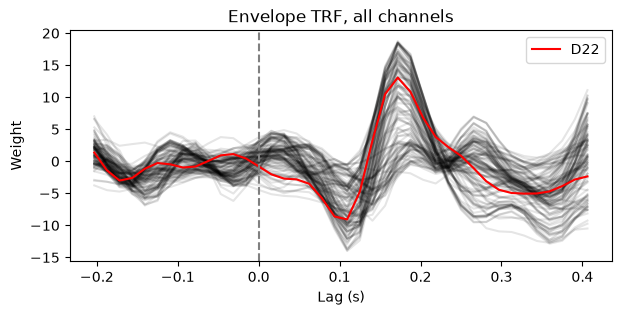

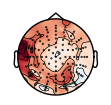

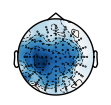

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(lags, trf.T, color="k", alpha=0.1)
ax.plot(lags, trf[best], color="r", label=raw.ch_names[best])
ax.axvline(0, ls="--", color="grey")
ax.set(xlabel="Lag (s)", ylabel="Weight", title="Envelope TRF, all channels")
ax.legend()

mne.viz.plot_topomap(scores, raw.info)                  # where prediction works best
ix = np.argmin(np.abs(lags - 0.1))
mne.viz.plot_topomap(trf[:, ix], raw.info)              # TRF weights at 100 ms
plt.show()

In [5]:
for lam in [1e-1, 1e1, 1e3, 1e5]:
    s = []
    for train, test in KFold(n_splits=5).split(X):
        r = ReceptiveField(tmin, tmax, sfreq, estimator=lam, scoring="corrcoef")
        r.fit(X[train], Y[train])
        s.append(r.score(X[test], Y[test]).mean())
    print(f"lambda = {lam:g}: mean r = {np.mean(s):.4f}")

Fitting 1 epochs, 1 channels


100%|██████████| Sample : 2/2 [00:00<00:00,   48.43it/s]

Fitting 1 epochs, 1 channels



100%|██████████| Sample : 2/2 [00:00<00:00,   83.35it/s]

Fitting 1 epochs, 1 channels


...

Fitting 1 epochs, 1 channels


100%|██████████| Sample : 2/2 [00:00<00:00,   93.44it/s]


Fitting 1 epochs, 1 channels


100%|██████████| Sample : 2/2 [00:00<00:00,   92.07it/s]


lambda = 100000: mean r = 0.0136


Fitting 1 epochs, 128 channels


100%|██████████| Sample : 8384/8384 [00:00<00:00, 8526.97it/s] 


Fitting 1 epochs, 128 channels


100%|██████████| Sample : 8384/8384 [00:01<00:00, 8043.94it/s]


Fitting 1 epochs, 128 channels


...

Fitting 1 epochs, 128 channels


100%|██████████| Sample : 8384/8384 [00:01<00:00, 8277.47it/s]


Fitting 1 epochs, 128 channels


100%|██████████| Sample : 8384/8384 [00:00<00:00, 8762.24it/s] 


Envelope reconstruction r per fold: [0.188 0.203 0.14  0.234 0.157]


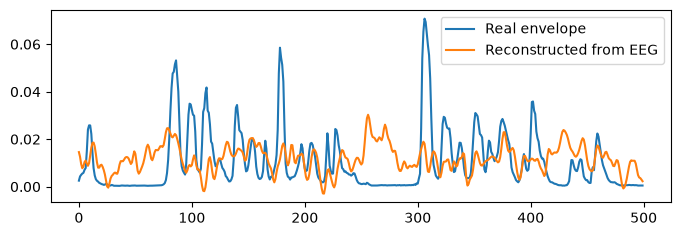

In [6]:
sr = ReceptiveField(-0.2, 0.0, sfreq, feature_names=raw.ch_names, estimator=1e4, scoring="corrcoef", patterns=True)

dec_scores = []
for train, test in KFold(n_splits=5).split(X):
    sr.fit(Y[train], X[train])               # note: X and Y are swapped
    dec_scores.append(sr.score(Y[test], X[test])[0])
print("Envelope reconstruction r per fold:", np.round(dec_scores, 3))

pred = sr.predict(Y[test])
plt.figure(figsize=(8, 2.5))
plt.plot(X[test][:500, 0], label="Real envelope")
plt.plot(pred[:500, 0], label="Reconstructed from EEG")
plt.legend(); plt.show()